# Task 3 — Compare the two segmentation methods

This notebook compares Task 2 masks with the Task 1 masks. It calculates overlap scores, shows where the methods disagree, and displays difficult examples.

## Local files used by this notebook

The default paths point to the folders in this repository: `Dataset/`, `Task1/task1_results/task1_results/combined_masks/`, and `Task2/task2_results/`. Save or extract the Task 2 output folder at that last location before running this notebook. If you keep it elsewhere, change `TASK2_DIR` in the setup cell.

Task 1 masks are model-made references, not hand-labelled truth, so a disagreement does not automatically mean Task 2 is wrong.


In [1]:
from pathlib import Path
import os, json, math, warnings
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path.cwd().resolve()
REPO_ROOT = ROOT if (ROOT/"Task1").exists() else ROOT.parent if (ROOT.parent/"Task1").exists() else ROOT
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_result_folder(name, required_file, roots):
    """Look for a result folder that actually contains the expected files."""
    for root in roots:
        if not root.exists():
            continue
        for folder in sorted(root.rglob(name)):
            if folder.is_dir() and any(folder.rglob(required_file)):
                return folder
    return None

# These are the folders used in the local repository.
DATASET_DIR = Path(os.environ["EGG_DATASET_DIR"]) if os.environ.get("EGG_DATASET_DIR") else REPO_ROOT/"Dataset"
TASK1_MASK_DIR = Path(os.environ["TASK1_MASK_DIR"]) if os.environ.get("TASK1_MASK_DIR") else REPO_ROOT/"Task1/task1_results/task1_results/combined_masks"
TASK2_DIR = Path(os.environ["TASK2_DIR"]) if os.environ.get("TASK2_DIR") else None

# If the Task 2 outputs were saved to another local folder, try to find them in the repository.
if not TASK1_MASK_DIR.exists():
    TASK1_MASK_DIR = find_result_folder("combined_masks", "*_mask.png", [REPO_ROOT])
if TASK2_DIR is None:
    TASK2_DIR = find_result_folder("task2_results", "*_pred.png", [REPO_ROOT])
if TASK2_DIR is None:
    # Also accept the output folder itself if it was renamed after extracting the zip.
    for candidate in [REPO_ROOT/"Task2", REPO_ROOT/"Task2/task2_results"]:
        if candidate.exists() and any(candidate.rglob("*_pred.png")):
            TASK2_DIR = candidate
            break
if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Image dataset not found at {DATASET_DIR}. Set EGG_DATASET_DIR to the local Dataset folder.")
if TASK1_MASK_DIR is None or not TASK1_MASK_DIR.exists():
    raise FileNotFoundError("Task 1 combined masks not found. Check Task1/task1_results/task1_results/combined_masks or set TASK1_MASK_DIR.")
if TASK2_DIR is None:
    raise FileNotFoundError("Task 2 predictions not found. Extract task2_results under Task2/ or set TASK2_DIR to the folder containing pred_masks/.")
PRED_DIR = TASK2_DIR/"pred_masks"
if not PRED_DIR.exists():
    nested_pred_dirs = list(TASK2_DIR.rglob("pred_masks"))
    if nested_pred_dirs: PRED_DIR = nested_pred_dirs[0]
if not PRED_DIR.exists():
    raise FileNotFoundError(f"No pred_masks folder found under {TASK2_DIR}. Make sure the saved Task 2 output is extracted.")
print("Repository:", REPO_ROOT, "\nImages:", DATASET_DIR, "\nTask 1 masks:", TASK1_MASK_DIR, "\nTask 2 predictions:", PRED_DIR)


Repository: C:\DewangData\NoshRobotics 
Images: C:\DewangData\NoshRobotics\Dataset 
Task 1 masks: C:\DewangData\NoshRobotics\Task1\task1_results\task1_results\combined_masks 
Task 2 predictions: C:\DewangData\NoshRobotics\Task2\task2_results\task2_results\pred_masks


## Find matching images and masks

Images and masks are paired by filename. The setup cell uses the local repository folders by default and looks inside an extracted Task 2 output folder for `pred_masks/`. Images without both masks are skipped.

In [2]:
images = sorted(p for p in DATASET_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
refs = {p.name[:-len("_mask.png")]: p for p in TASK1_MASK_DIR.rglob("*_mask.png")}
preds = {p.name[:-len("_pred.png")]: p for p in PRED_DIR.rglob("*_pred.png")}
rows, cases = [], []
for image_path in images:
    stem = image_path.stem
    ref_path, pred_path = refs.get(stem), preds.get(stem)
    if ref_path is None or pred_path is None: continue
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    gt = cv2.imread(str(ref_path), cv2.IMREAD_GRAYSCALE) > 127
    pred = cv2.imread(str(pred_path), cv2.IMREAD_GRAYSCALE) > 127
    if gt.shape != image.shape[:2]: gt = cv2.resize(gt.astype(np.uint8), (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    if pred.shape != image.shape[:2]: pred = cv2.resize(pred.astype(np.uint8), (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
    eps = 1e-9
    rows.append({"image": image_path.name, "TP": tp, "FP": fp, "FN": fn,
        "IoU": tp/(tp+fp+fn+eps), "Dice": 2*tp/(2*tp+fp+fn+eps),
        "Precision": tp/(tp+fp+eps), "Recall": tp/(tp+fn+eps),
        "GT_pixels": int(gt.sum()), "Pred_pixels": int(pred.sum())})
    cases.append((image_path.name, image, gt, pred))
df = pd.DataFrame(rows)
if df.empty: raise ValueError("No matching image/reference/prediction stems. Check the supplied result folders.")
print(f"Paired {len(df)} images; unmatched images: {len(images)-len(df)}")
display(df.head())


Paired 109 images; unmatched images: 1


,image,TP,FP,FN,IoU,Dice,Precision,Recall,GT_pixels,Pred_pixels
0,not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcd...,91045,775,308,0.988245,0.994088,0.991560,0.996628,91353,91820
1,not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b...,19,45891,14216,0.000316,0.000632,0.000414,0.001335,14235,45910
2,not_damaged_14_jpg.rf.dc96559078b03433d2b65e50...,19303,213,9258,0.670849,0.803004,0.989086,0.675852,28561,19516
3,not_damaged_152_jpg.rf.a57edb18d395ce87e23f7ab...,20150,116,1892,0.909378,0.952539,0.994276,0.914164,22042,20266
4,not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74...,22586,50,12885,0.635849,0.777393,0.997791,0.636746,35471,22636


## What do the scores say?

We compare the two masks pixel by pixel. Each image gets the same weight in the averages, whether its egg is large or small. These four measures are commonly used for segmentation and together show overlap, extra mask area, and missed mask area.

- **IoU (intersection over union):** how much the two masks overlap compared with the area covered by either mask. Higher is better.
- **Dice:** another overlap score. It is usually a little higher than IoU for the same pair of masks.
- **Precision:** when Task 2 marks a pixel as egg, how often Task 1 also marks it as egg. Low precision often means the mask included extra background.
- **Recall:** of the pixels Task 1 marked as egg, how many Task 2 found. Low recall often means part of the egg was missed.

The assignment asks for relevant segmentation metrics and an analysis; it does not set a required score or pass mark. The interval below is a rough estimate of how the average IoU might vary across images.

In [3]:
def bootstrap_ci(values, n=5000, seed=42):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    samples = values[rng.integers(0, len(values), (n, len(values)))].mean(axis=1)
    return np.percentile(samples, [2.5, 97.5])

metric_cols = ["IoU", "Dice", "Precision", "Recall"]
summary = pd.DataFrame({"Mean": df[metric_cols].mean(), "Median": df[metric_cols].median(),
                        "Std": df[metric_cols].std(ddof=1)})
iou_ci = bootstrap_ci(df.IoU)
summary.loc["IoU", "95% bootstrap CI"] = str(np.round(iou_ci, 4))

readable = pd.DataFrame([
    {"Measure": "Mask overlap (IoU)", "Average": f"{df.IoU.mean():.1%}", "Median image": f"{df.IoU.median():.1%}", "In plain words": "How much the masks cover the same area."},
    {"Measure": "Overlap (Dice)", "Average": f"{df.Dice.mean():.1%}", "Median image": f"{df.Dice.median():.1%}", "In plain words": "Another way to score how closely the masks overlap."},
    {"Measure": "Extra-area check (precision)", "Average": f"{df.Precision.mean():.1%}", "Median image": f"{df.Precision.median():.1%}", "In plain words": "How often predicted egg pixels also belong to the reference mask."},
    {"Measure": "Missed-area check (recall)", "Average": f"{df.Recall.mean():.1%}", "Median image": f"{df.Recall.median():.1%}", "In plain words": "How much of the reference mask the prediction found."},
])
print(f"Images compared: {len(df)}")
print(f"Average IoU: {df.IoU.mean():.1%} (rough 95% range: {iou_ci[0]:.1%} to {iou_ci[1]:.1%})")
display(readable)
below_half = int((df.IoU < .5).sum())
below_tenth = int((df.IoU < .1).sum())
print(f"{len(df)-below_half} images scored 0.50 IoU or higher; {below_half} scored below 0.50; {below_tenth} scored below 0.10.")
print("The 0.50 and 0.10 cutoffs are just convenient ways to find difficult examples; the assignment does not define them as pass/fail limits.")
worst_table = df.sort_values("IoU").head(10)[["image", "IoU", "Dice", "Precision", "Recall", "FP", "FN"]].copy()
worst_table = worst_table.rename(columns={"image":"Image", "IoU":"Mask overlap", "Dice":"Dice overlap", "Precision":"Precision", "Recall":"Recall", "FP":"Extra pixels", "FN":"Missed pixels"})
display(worst_table.round(3))


Images compared: 109
Average IoU: 74.5% (rough 95% range: 68.6% to 80.1%)
89 images scored 0.50 IoU or higher; 20 scored below 0.50; 8 scored below 0.10.
The 0.50 and 0.10 cutoffs are just convenient ways to find difficult examples; the assignment does not define them as pass/fail limits.


,Measure,Average,Median image,In plain words
0,Mask overlap (IoU),74.5%,87.8%,How much the masks cover the same area.
1,Overlap (Dice),80.8%,93.5%,Another way to score how closely the masks ove...
2,Extra-area check (precision),84.3%,98.8%,How often predicted egg pixels also belong to ...
3,Missed-area check (recall),84.2%,98.1%,How much of the reference mask the prediction ...


,Image,Mask overlap,Dice overlap,Precision,Recall,Extra pixels,Missed pixels
58,not_damaged_20_jpg.rf.5e8498e31e0e596d64f6185f...,0.000,0.000,0.000,0.000,15078,20171
32,not_damaged_131_jpg.rf.4ac62f5b18b131bac463f70...,0.000,0.000,0.000,0.000,21528,78361
91,not_damaged_119_jpg.rf.6758625c4b939166ca105d0...,0.000,0.000,0.000,0.000,33832,70120
1,not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b...,0.000,0.001,0.000,0.001,45891,14216
61,not_damaged_24_jpg.rf.a557aeb67c480dc55479509a...,0.001,0.001,0.001,0.001,25636,42829
26,not_damaged_123_jpg.rf.11d40a86277d3ab3fce1c5c...,0.004,0.009,0.006,0.015,48052,19682
67,not_damaged_32_jpg.rf.15f5702d8602844d8d866d22...,0.050,0.096,0.050,1.000,378544,0
60,not_damaged_22_jpg.rf.427da4fa2858bf0484b60777...,0.088,0.162,0.088,0.990,109612,104
23,not_damaged_116_jpg.rf.43fecd96347e2129115fcee...,0.102,0.185,0.102,0.992,166758,153
85,not_damaged_135_jpg.rf.a6d81ffb82470e031fb3ab4...,0.108,0.196,0.109,0.988,128164,186


## Plots and examples of difficult images

The charts show whether results are usually strong or whether a few difficult images pull down the average. In the example overlays, **green** means both masks agree, **red** means Task 2 marked extra pixels, and **blue** means Task 2 missed pixels that were in the Task 1 mask.

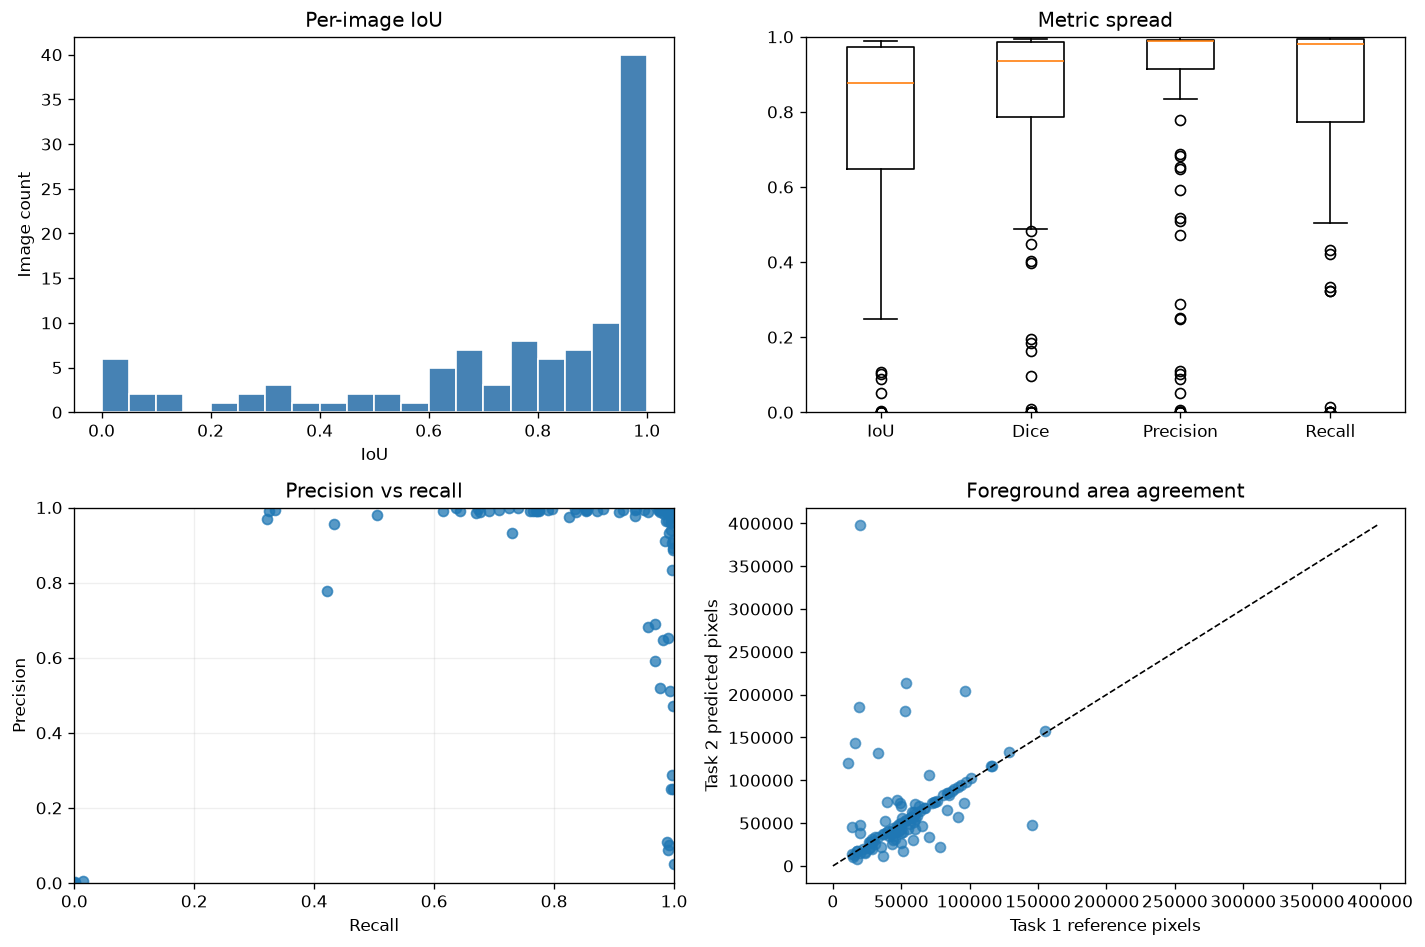

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].hist(df.IoU, bins=np.linspace(0,1,21), color="steelblue", edgecolor="white"); axes[0,0].set(title="Per-image IoU", xlabel="IoU", ylabel="Image count")
axes[0,1].boxplot([df[c] for c in metric_cols], tick_labels=metric_cols); axes[0,1].set(title="Metric spread", ylim=(0,1))
axes[1,0].scatter(df.Recall, df.Precision, alpha=.75); axes[1,0].set(title="Precision vs recall", xlabel="Recall", ylabel="Precision", xlim=(0,1), ylim=(0,1)); axes[1,0].grid(alpha=.2)
axes[1,1].scatter(df.GT_pixels, df.Pred_pixels, alpha=.65); lim=max(df.GT_pixels.max(),df.Pred_pixels.max()); axes[1,1].plot([0,lim],[0,lim],"k--",lw=1); axes[1,1].set(title="Foreground area agreement", xlabel="Task 1 reference pixels", ylabel="Task 2 predicted pixels")
plt.tight_layout(); plt.show()


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [7.0..245.1].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [5.0..252.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [4.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [2.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


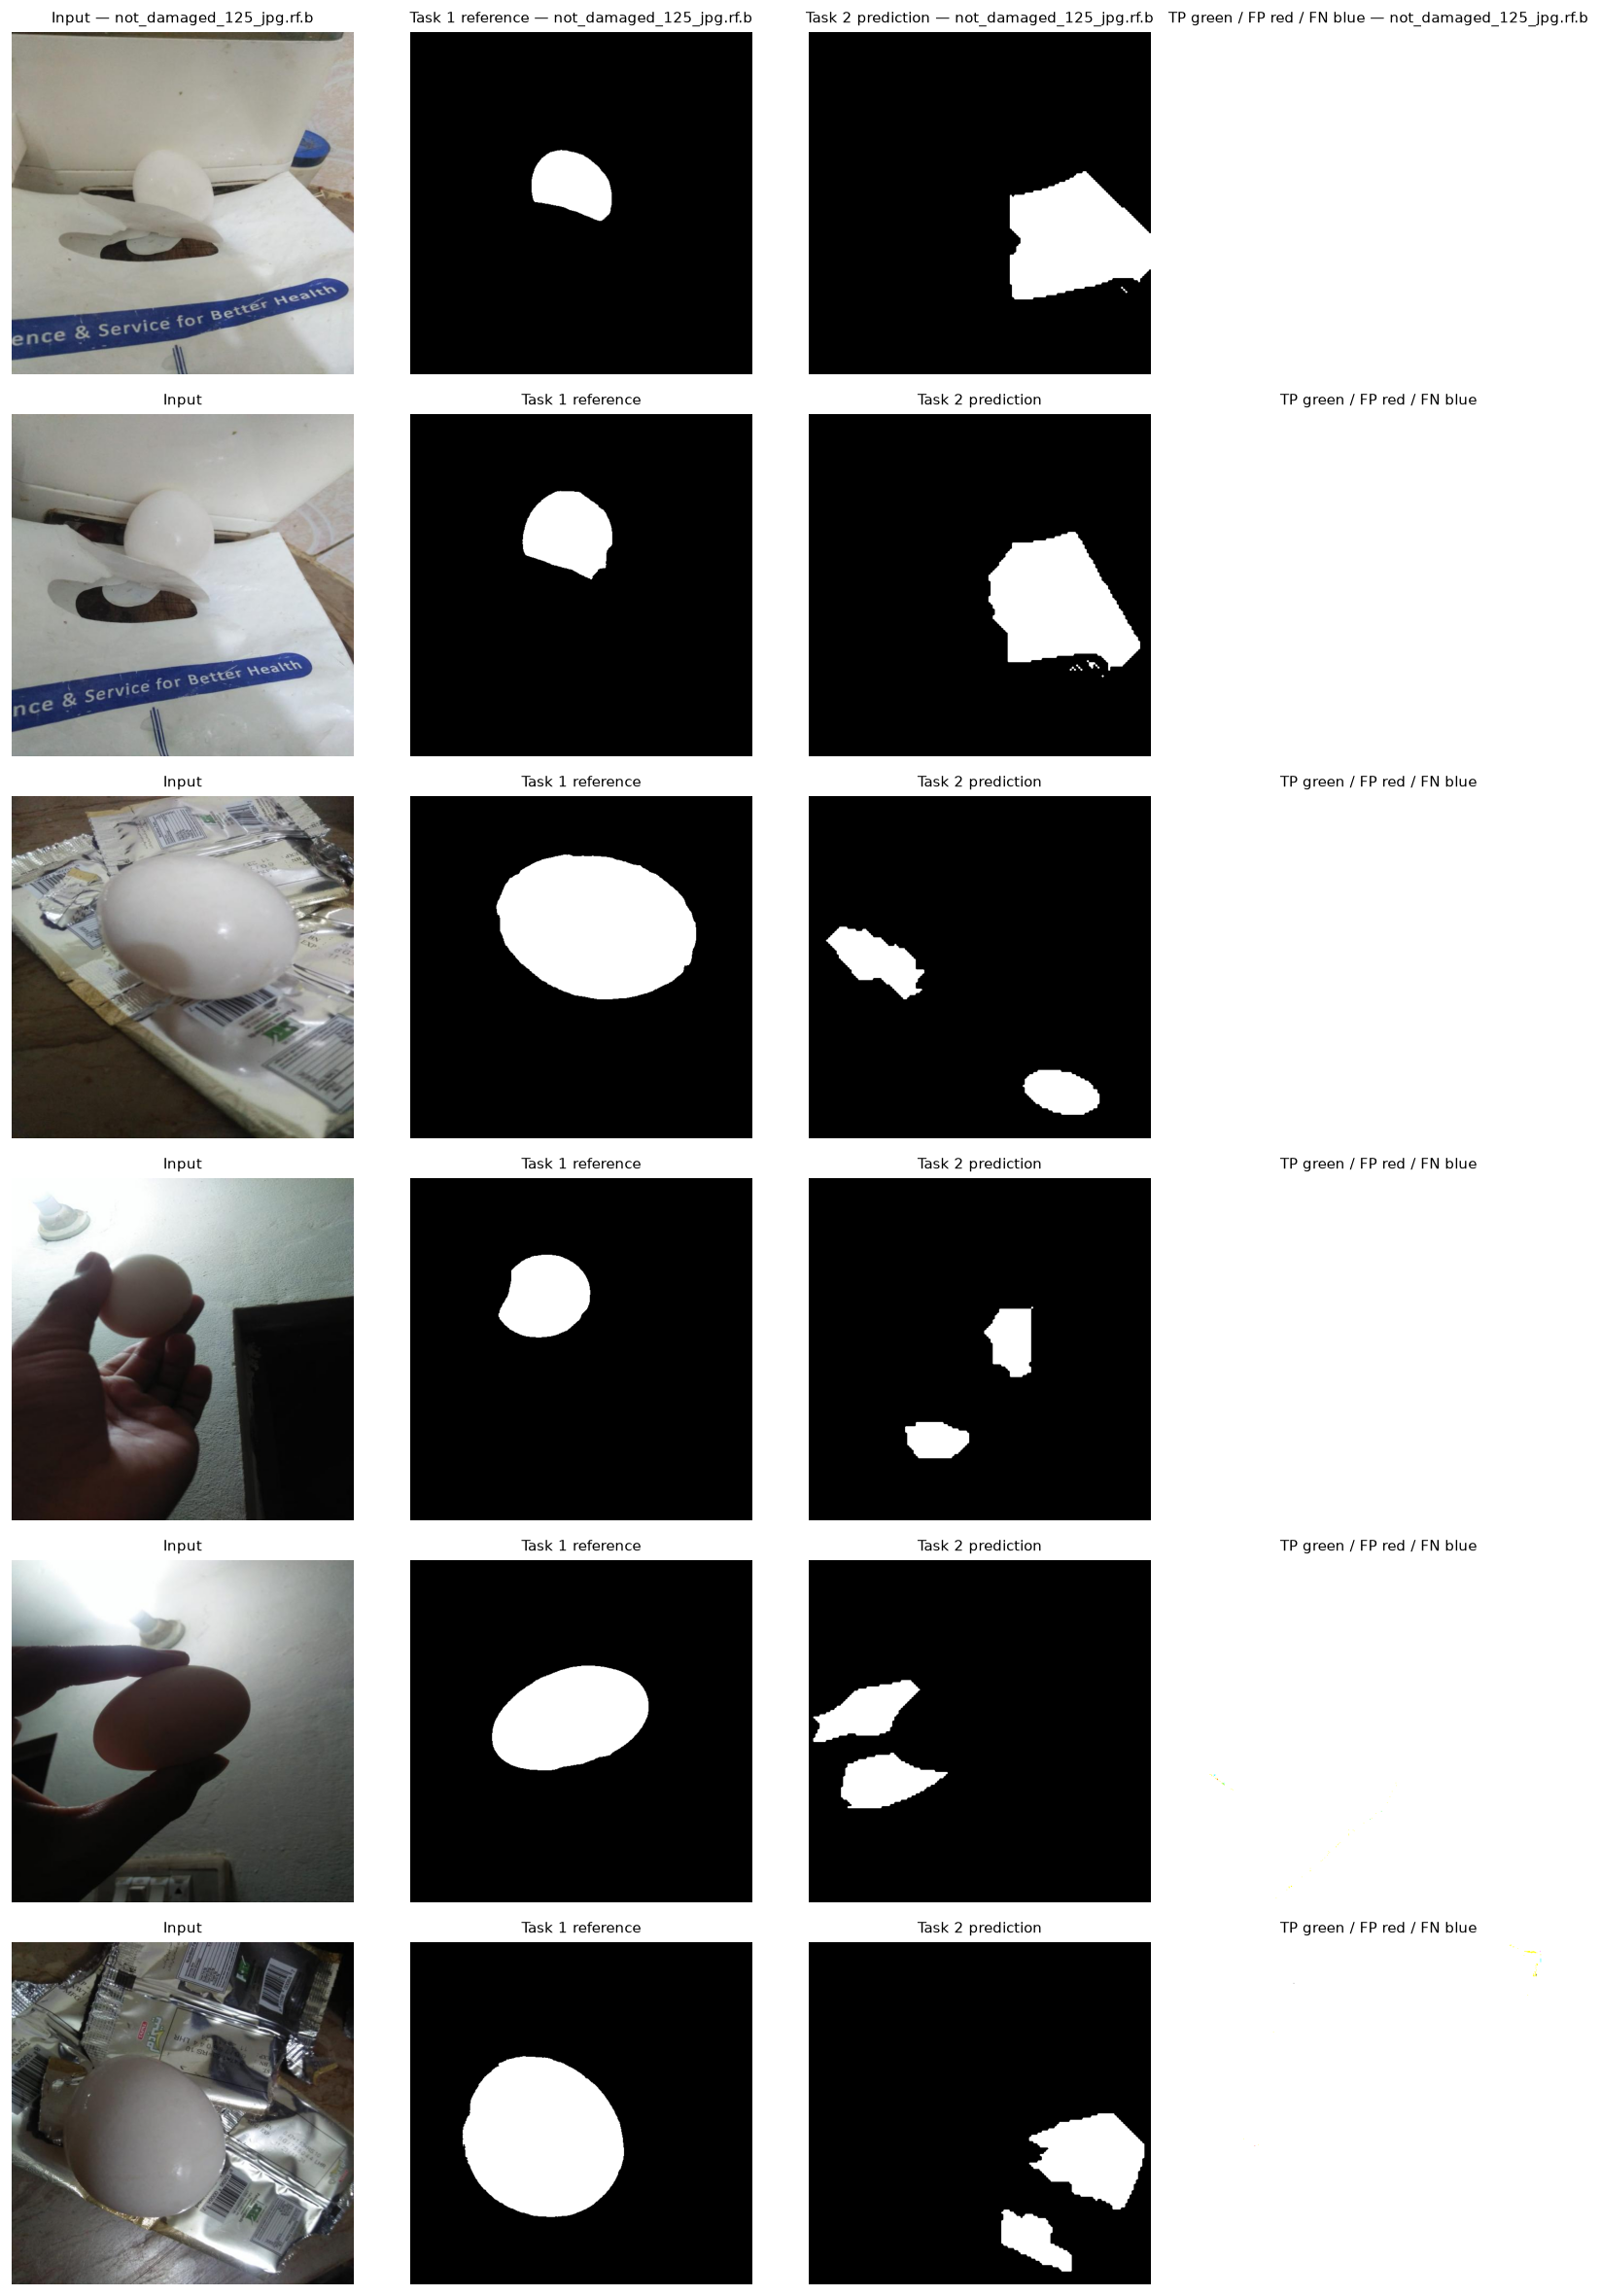

In [5]:
worst = set(df.nsmallest(min(6,len(df)), "IoU").image)
selected = [x for x in cases if x[0] in worst]
fig, axes = plt.subplots(len(selected), 4, figsize=(14, 3.3*len(selected)), squeeze=False)
for row, (name, img, gt, pred) in enumerate(selected):
    overlay = img.astype(np.float32).copy()
    for mask, color in [(pred & gt,(0,210,0)),(pred & ~gt,(255,0,0)),(~pred & gt,(0,90,255))]: overlay[mask] = .45*overlay[mask] + .55*np.array(color)
    for col, view, title in [(0,img,"Input"),(1,gt,"Task 1 reference"),(2,pred,"Task 2 prediction"),(3,overlay,"TP green / FP red / FN blue")]:
        axes[row,col].imshow(view, cmap="gray" if col in [1,2] else None); axes[row,col].set_title(title if row else f"{title} — {name[:24]}", fontsize=9); axes[row,col].axis("off")
plt.tight_layout(); plt.show()


## What we can conclude

In this run, the average IoU is **74.5%**, while the median image is **87.8%**. The median being higher than the average tells us that many images match well, but some difficult images lower the overall average. The score table also shows precision and recall are both about **84%** on average: the method makes both kinds of errors, adding some extra area and missing some reference area.

The examples above help show what those errors look like. Use the red and blue areas to describe the specific failures in your report. Likely improvements to investigate include rejecting background objects with egg-like outlines, handling eggs that touch or overlap, and checking whether the Task 1 reference mask itself is accurate.

**Important:** Task 1 masks were generated by a model, not drawn by a person. These scores tell us how closely Task 2 agrees with Task 1; they cannot prove which mask is correct. Also, this report includes all 109 images whose saved Task 2 predictions exist, including the images used during Task 2 development, so it is an analysis of the completed dataset rather than a separate untouched test.

The CSV files are saved in `task3_analysis/`. The per-image file is useful for finding particular cases; the summary file contains the average, median, and uncertainty estimate.

In [6]:
OUT_DIR = Path(os.environ.get("TASK3_OUT_DIR", ROOT / "task3_analysis")); OUT_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT_DIR / "per_image_metrics.csv", index=False)
summary.to_csv(OUT_DIR / "metric_summary.csv")
print("Saved CSV reports to", OUT_DIR.resolve())


Saved CSV reports to C:\DewangData\NoshRobotics\task3_analysis
